<a href="https://colab.research.google.com/github/Tdanso/new-google-colab-/blob/main/Running_SQL_queries_from_Python_in_a_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import sqlite3

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')
df

In [3]:
conn = sqlite3.connect(':memory:')


In [4]:
df.to_sql('passengers', conn, index=False)


891

df.to_sql() converts the DataFrame into a database table named 'passengers'. The index=False argument tells pandas not to include the DataFrame's row numbers as a column. That index belongs to Python, not your data.

Here's all four steps together:

In [7]:
import pandas as pd
import sqlite3

df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')
conn = sqlite3.connect(':memory:')
df.to_sql('passengers', conn, index=False)

891

In [8]:
query = 'SELECT * FROM passengers LIMIT 5'


In [9]:
result = pd.read_sql(query, conn)

In [10]:
print(result)


   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500  None        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250  None        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500  None        S  


The output is a regular pandas DataFrame. You can filter it, transform it, or visualize it — every pandas tool you learned in Sprint 3 applies here.

Here's all three steps together:



In [ ]:
query = 'SELECT * FROM passengers LIMIT 5'
result = pd.read_sql(query, conn)
print(result)

In [ ]:
query = 'SELECT * FROM passengers LIMIT 5'
result = pd.read_sql(query, conn)
print(result)

In [ ]:
query = ''' SELECT
        name,
        age,
        sex
FROM
        passengers
LIMIT 10'''
result = pd.read_sql(query, conn)
print(result.head(10))

In [ ]:
query = ''' SELECT
    name,
    age,
    sex,
    COUNT(name) AS Name_count
FROM
    passengers
GROUP BY
    sex
ORDER BY
    Name_count DESC
LIMIT 10'''
result = pd.read_sql(query, conn)
print(result)



In [ ]:
query = ''' SELECT
    name,
    age,
    sex,
    Survived,
    COUNT(name) AS Name_count
FROM
    passengers
GROUP BY
    Survived
ORDER BY
    Name_count DESC
LIMIT 10'''
result = pd.read_sql(query, conn)
print(result)

In [11]:
query = '''
SELECT
    Pclass,
    COUNT(*) AS passenger_count,
    ROUND(AVG(Fare), 2) AS avg_fare,
    ROUND(AVG(Survived), 2) AS survival_rate
FROM passengers
GROUP BY Pclass
ORDER BY Pclass
'''
result = pd.read_sql(query, conn)
print(result)

   Pclass  passenger_count  avg_fare  survival_rate
0       1              216     84.15           0.63
1       2              184     20.66           0.47
2       3              491     13.68           0.24


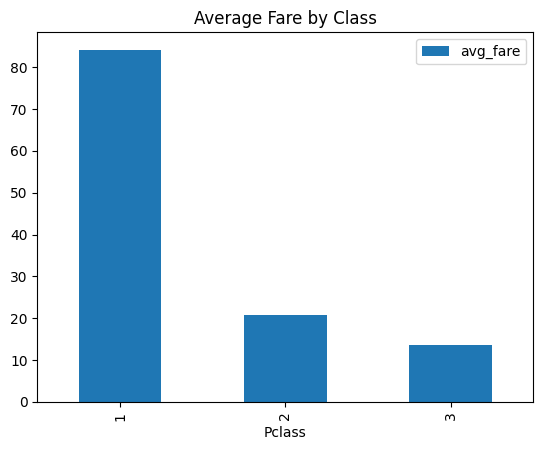

In [12]:
from matplotlib import pyplot as plt

result.plot(x='Pclass', y='avg_fare', kind='bar', title='Average Fare by Class')
plt.show()

Task 1
The Titanic dataset has been loaded and pushed to a SQLite database for you in the precode. Write a SQL query to find all female passengers who survived. Select only the Name, Age, and Fare columns. Assign the result to a variable called survivors and print the first 10 rows.

Hint: Use pd.read_sql() with a SELECT statement that includes WHERE Sex = 'female' AND Survived = 1. Don't forget to pass conn as the second argument.

In [14]:
import pandas as pd
import sqlite3

df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')
conn = sqlite3.connect(':memory:')
df.to_sql('passengers', conn, index=False)

# Write your SQL query and assign the result to 'survivors'
survivors = '''SELECT Name,
                       Age,
                       fare
                FROM passengers
                WHERE sex = 'female' AND survived = 1'''

# Read the result into a DataFrame and print the first 10 rows
survivors = pd.read_sql(survivors, conn)
print(survivors.head(10))

                                                Name   Age     Fare
0  Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0  71.2833
1                             Heikkinen, Miss. Laina  26.0   7.9250
2       Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0  53.1000
3  Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)  27.0  11.1333
4                Nasser, Mrs. Nicholas (Adele Achem)  14.0  30.0708
5                    Sandstrom, Miss. Marguerite Rut   4.0  16.7000
6                           Bonnell, Miss. Elizabeth  58.0  26.5500
7                   Hewlett, Mrs. (Mary D Kingcome)   55.0  16.0000
8                            Masselmani, Mrs. Fatima   NaN   7.2250
9                        McGowan, Miss. Anna "Annie"  15.0   8.0292


Task 2
Write a SQL query that calculates the number of passengers and the average fare for each embarkation port (Embarked). Round the average fare to 2 decimal places using ROUND(). Order the results by average fare in descending order. Assign the result to port_stats and print it.

In [16]:
import pandas as pd
import sqlite3


df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')
conn = sqlite3.connect(':memory:')
df.to_sql('passengers', conn, index=False)

# Write your SQL query
port_stats = ''' SELECT
                 Embarked,
                COUNT(*) AS passenger_count,
                ROUND(AVG(Fare), 2) AS avg_fare
      FROM   passengers
      GROUP BY Embarked
      ORDER BY avg_fare DESC
'''

# Read the result into a DataFrame and print it
port_stats = pd.read_sql(port_stats, conn)
print(port_stats)

  Embarked  passenger_count  avg_fare
0     None                2     80.00
1        C              168     59.95
2        S              644     27.08
3        Q               77     13.28
